# CafeSmart AI · Entrenamiento y experimentación

**Entrega 3 · Equipo 4**

Este cuaderno reproduce dos experimentos de pronóstico de unidades vendidas: uno diario y otro por franja horaria. Compara Random Forest y Gradient Boosting, con y sin clima, frente a dos reglas simples. Los datos de ventas y el histórico meteorológico están incluidos en el proyecto.

En VS Code, selecciona el kernel del entorno donde instalaste `requirements.txt` y ejecuta **Run All**. El cuaderno invoca los mismos módulos que los comandos de terminal.

## 1. Ubicar el proyecto

El cuaderno funciona si el kernel inicia en la raíz del repositorio o dentro de `notebooks/`. Busca la raíz a partir del directorio de ejecución, así que puedes mover la carpeta del proyecto.

In [1]:
import json
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

actual = Path.cwd()
raiz = next(
    (carpeta for carpeta in (actual, *actual.parents)
     if (carpeta / "src/models/train.py").is_file()
     and (carpeta / "requirements.txt").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abre en VS Code la carpeta raíz del proyecto y vuelve a ejecutar.")

os.chdir(raiz)
sys.path.insert(0, str(raiz))
from src.data.preprocess import preparar
from src.models.train import CORTE, FIN, entrenar
from src.models.predict import predecir

ventas = Path("data/raw/Coffee_Shop_Sales.csv")
clima = Path("data/raw/clima_nyc_2023.csv")
procesados = Path("data/processed")
modelos = Path("models")
evidencias = Path("evidencias")
diario = procesados / "ventas_diarias_por_producto.csv"
franjas = procesados / "ventas_por_franja.csv"
print("Archivos de entrada:", ventas.name, "y", clima.name)

Archivos de entrada: Coffee_Shop_Sales.csv y clima_nyc_2023.csv


## 2. Preparar los datos

`src/data/preprocess.py` agrupa las ventas por fecha, sucursal y tipo de producto. El segundo experimento agrega la franja horaria. El objetivo es `unidades`. El promedio móvil y el rezago usan solo ventas de los días previos. El clima se une por fecha y sucursal.

In [2]:
procesados.mkdir(parents=True, exist_ok=True)

panel_diario = preparar(ventas, clima)
panel_diario.to_csv(diario, index=False)

panel_franjas = preparar(ventas, clima, por_franja=True)
panel_franjas.to_csv(franjas, index=False)

columnas = [
    "fecha", "sucursal", "producto", "unidades",
    "unidades_lag7", "unidades_prom7", "temperatura_c", "lluvia_mm",
]
display(panel_diario.dropna(subset=["unidades_lag7"])[columnas].head())

CSV original: 149,116 filas, 11 columnas
Catálogo: 13 tipos, 39 pares sucursal-tipo
Combinaciones sin ventas completadas con cero: 1
Panel: 7,059 filas. Listas para entrenar: 6,786
CSV original: 149,116 filas, 11 columnas
Catálogo: 13 tipos, 39 pares sucursal-tipo
Combinaciones sin ventas completadas con cero: 1,334
Panel: 21,177 filas. Listas para entrenar: 20,358


,fecha,sucursal,producto,unidades,unidades_lag7,unidades_prom7,temperatura_c,lluvia_mm
7,2023-01-08,Astoria,Barista Espresso,20,29.0,30.000000,2.0375,0.0
188,2023-01-08,Astoria,Biscotti,13,5.0,6.428571,2.0375,0.0
369,2023-01-08,Astoria,Brewed Black tea,19,13.0,25.571429,2.0375,0.0
550,2023-01-08,Astoria,Brewed Chai tea,32,42.0,36.714286,2.0375,0.0
731,2023-01-08,Astoria,Brewed Green tea,8,15.0,12.714286,2.0375,0.0


## 3. Verificar la partición temporal

El ajuste usa tres cortes cronológicos dentro del periodo de entrenamiento. La prueba final empieza el 26 de mayo de 2023. Mantener juntas las observaciones de una misma fecha evita mezclar registros de ese día entre conjuntos.

In [3]:
resumen = []
for nombre, panel in [("Diario", panel_diario), ("Por franja", panel_franjas)]:
    listas = panel.dropna(subset=["unidades_lag7", "unidades_prom7"])
    train = listas.loc[listas.fecha.le(CORTE)]
    test = listas.loc[listas.fecha.gt(CORTE) & listas.fecha.le(FIN)]
    for etiqueta, conjunto in [("Entrenamiento", train), ("Prueba", test)]:
        resumen.append({
            "Experimento": nombre,
            "Conjunto": etiqueta,
            "Desde": conjunto.fecha.min().date(),
            "Hasta": conjunto.fecha.max().date(),
            "Filas": len(conjunto),
        })
display(pd.DataFrame(resumen))

,Experimento,Conjunto,Desde,Hasta,Filas
0,Diario,Entrenamiento,2023-01-08,2023-05-25,5382
1,Diario,Prueba,2023-05-26,2023-06-30,1404
2,Por franja,Entrenamiento,2023-01-08,2023-05-25,16146
3,Por franja,Prueba,2023-05-26,2023-06-30,4212


## 4. Entrenar y guardar los modelos

Cada corrida calcula el promedio histórico y el promedio de siete días como referencias. Después ajusta los modelos de árboles, prueba las versiones con y sin clima y guarda cada pipeline `.joblib`.

El codificador de categorías viaja dentro de cada pipeline. Los regresores de árboles de este proyecto trabajan con las variables numéricas en su escala original.

In [4]:
print("Experimento diario")
entrenar(diario, modelos, evidencias)

Experimento diario
Train: 5,382 filas, 2023-01-08 a 2023-05-25
Test: 1,404 filas, 2023-05-26 a 2023-06-30


Ajuste random_forest {'n_estimators': 200, 'min_samples_leaf': 1}: MAE validación 8.465
Ajuste random_forest {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5}: MAE validación 8.319
Ajuste gradient_boosting {'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.05, 'min_samples_leaf': 5}: MAE validación 8.048
Ajuste gradient_boosting {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'min_samples_leaf': 10}: MAE validación 8.037
promedio_historico: MAE Train 7.906 | MAE Test 14.846 | acierto top 5 4.111/5
promedio_7d: MAE Train 6.477 | MAE Test 8.622 | acierto top 5 4.093/5
Entrenando random_forest_sin_clima con {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5}
random_forest_sin_clima: MAE Train 4.958 | MAE Test 9.096 | acierto top 5 4.102/5
Guardado: models\random_forest_sin_clima.joblib
Entrenando random_forest_con_clima con {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5}
random_forest_con_clima: MAE Train 4.638 | MAE Test 9.069 | acie

In [5]:
print("Experimento por franja horaria")
entrenar(franjas, modelos / "franjas", evidencias / "franjas")

Experimento por franja horaria
Train: 16,146 filas, 2023-01-08 a 2023-05-25
Test: 4,212 filas, 2023-05-26 a 2023-06-30
Ajuste random_forest {'n_estimators': 200, 'min_samples_leaf': 1}: MAE validación 5.113
Ajuste random_forest {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5}: MAE validación 4.897
Ajuste gradient_boosting {'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.05, 'min_samples_leaf': 5}: MAE validación 5.059
Ajuste gradient_boosting {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'min_samples_leaf': 10}: MAE validación 4.990
promedio_historico: MAE Train 4.251 | MAE Test 6.499 | acierto top 5 3.769/5
promedio_7d: MAE Train 4.003 | MAE Test 5.525 | acierto top 5 3.645/5
Entrenando random_forest_sin_clima con {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5}
random_forest_sin_clima: MAE Train 3.198 | MAE Test 5.391 | acierto top 5 3.620/5
Guardado: models\franjas\random_forest_sin_clima.joblib
Entrenando random_forest_con_clima con 

## 5. Comparar las métricas

Un MAE más bajo indica una menor desviación promedio en unidades vendidas. El acierto del menú cuenta cuántos tipos de producto coinciden con los cinco más vendidos. El candidato que usa la demo se elige con la validación interna. La columna de prueba permite ver cómo rindió después de la selección.

In [6]:
columnas_metricas = {
    "modelo": "Modelo",
    "mae_validacion": "MAE validación",
    "mae_train": "MAE entrenamiento",
    "mae_test": "MAE prueba",
    "top5_test": "Acierto top 5",
    "entrenamiento_s": "Entrenamiento (s)",
    "inferencia_ms": "Inferencia (ms)",
}

for nombre, carpeta, carpeta_modelos in [
    ("Diario", evidencias, modelos),
    ("Por franja", evidencias / "franjas", modelos / "franjas"),
]:
    seleccion = json.loads((carpeta_modelos / "seleccion.json").read_text(encoding="utf-8"))
    tabla = pd.read_csv(carpeta / "metricas.csv").sort_values("mae_test")
    print(f"{nombre} | Candidato elegido en validación: {seleccion['seleccionado']}")
    print(f"Menor MAE en prueba: {tabla.iloc[0].modelo}")
    display(tabla[list(columnas_metricas)].rename(columns=columnas_metricas).round(3))

Diario | Candidato elegido en validación: gradient_boosting_con_clima
Menor MAE en prueba: promedio_7d


,Modelo,MAE validación,MAE entrenamiento,MAE prueba,Acierto top 5,Entrenamiento (s),Inferencia (ms)
1,promedio_7d,NaN,6.477,8.622,4.093,NaN,NaN
4,gradient_boosting_sin_clima,8.037,6.027,9.052,4.056,1.567,5.018
3,random_forest_con_clima,8.190,4.638,9.069,4.056,4.907,25.756
2,random_forest_sin_clima,8.319,4.958,9.096,4.102,3.316,28.530
5,gradient_boosting_con_clima,7.935,5.892,9.111,4.074,2.038,5.101
0,promedio_historico,NaN,7.906,14.846,4.111,NaN,NaN


Por franja | Candidato elegido en validación: random_forest_con_clima
Menor MAE en prueba: gradient_boosting_sin_clima


,Modelo,MAE validación,MAE entrenamiento,MAE prueba,Acierto top 5,Entrenamiento (s),Inferencia (ms)
4,gradient_boosting_sin_clima,4.990,3.692,5.284,3.648,4.820,5.238
5,gradient_boosting_con_clima,5.019,3.593,5.389,3.670,6.769,5.505
2,random_forest_sin_clima,4.897,3.198,5.391,3.620,10.373,23.596
3,random_forest_con_clima,4.875,2.983,5.491,3.614,15.646,28.567
1,promedio_7d,NaN,4.003,5.525,3.645,NaN,NaN
0,promedio_historico,NaN,4.251,6.499,3.769,NaN,NaN


## 6. Ver la curva MAE en el cuaderno

Las curvas muestran cómo cambia el error al añadir árboles al Gradient Boosting. Cada figura se calcula en el último corte temporal de validación del experimento. Si el error de entrenamiento sigue bajando y el de validación deja de mejorar, los árboles adicionales aportan poco a ese corte.

Experimento diario


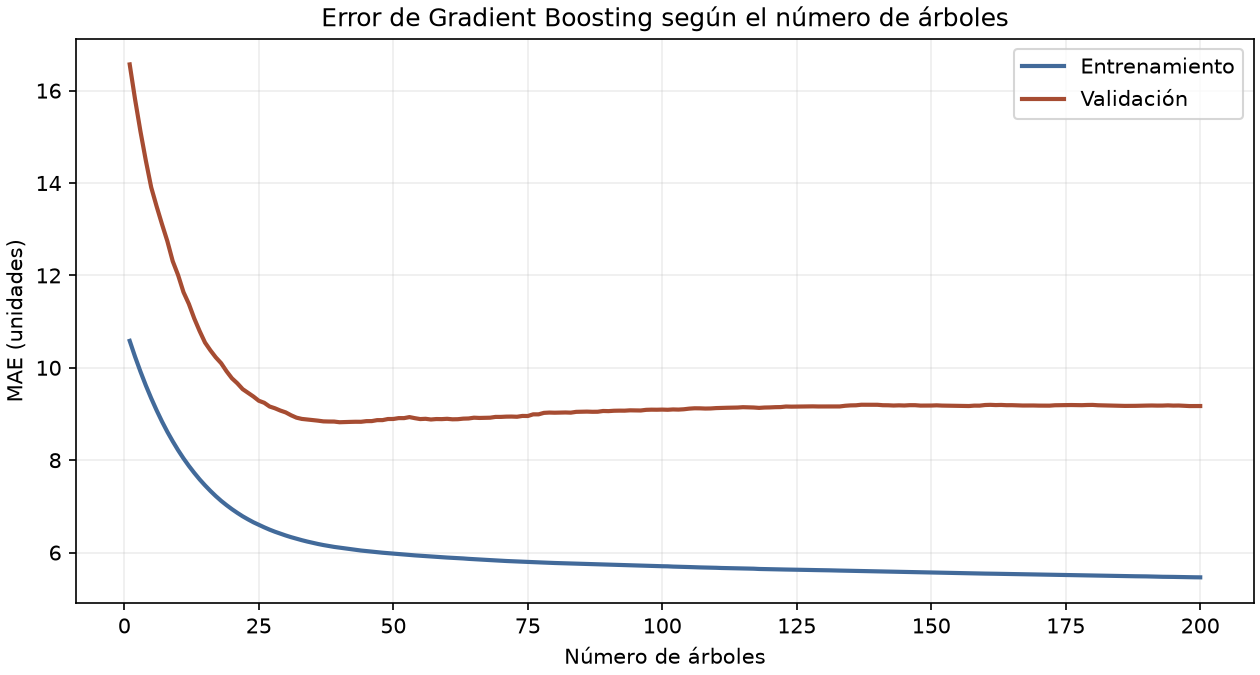

Experimento por franja horaria


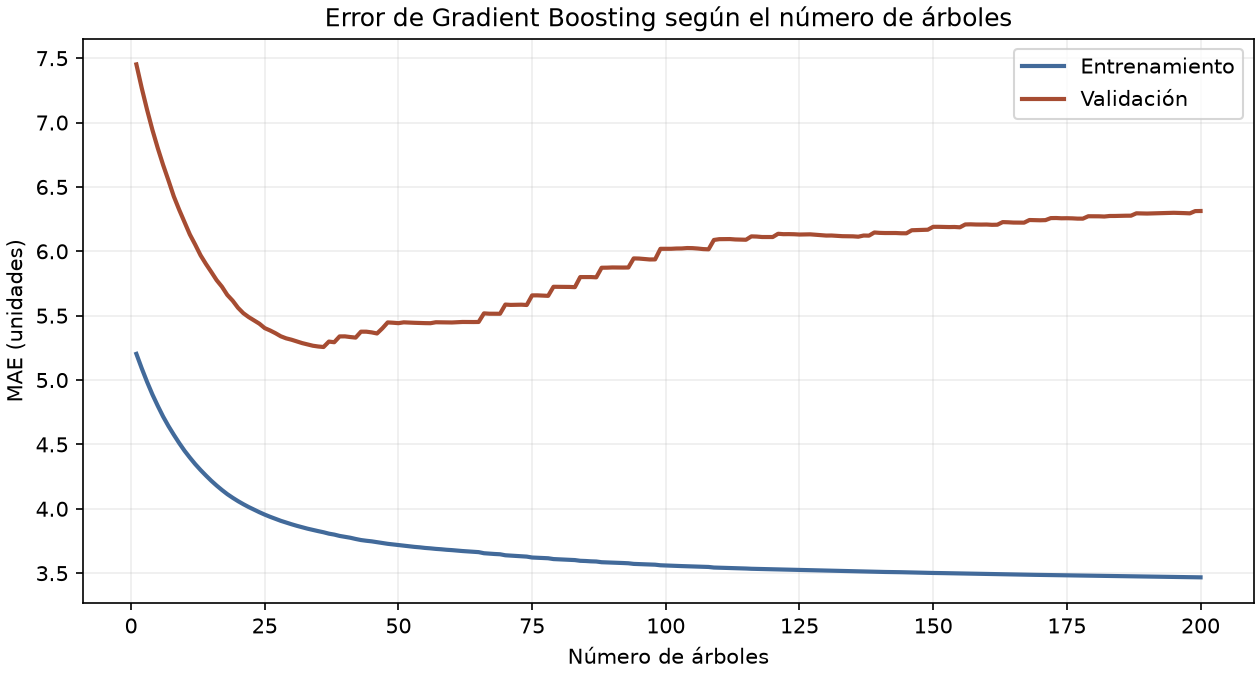

In [7]:
print("Experimento diario")
display(Image(filename=str(evidencias / "curva_mae.png"), width=820))

print("Experimento por franja horaria")
display(Image(filename=str(evidencias / "franjas/curva_mae.png"), width=820))

## 7. Probar el menú recomendado

La misma función `predecir()` carga los pipelines guardados. La segunda llamada selecciona la franja de la mañana.

In [8]:
caso = {"sucursal": "Hell's Kitchen", "fecha": "2023-06-15"}
for entrada in [caso, {**caso, "franja": "06:00–10:59"}]:
    salida = predecir(entrada)
    print(f"{salida['franja'] or 'Día completo'} | {salida['prediccion']:.2f} unidades estimadas")
    display(pd.DataFrame(salida["menu_top5"]))

Día completo | 572.92 unidades estimadas


,producto,categoria,unidades,nivel
0,Barista Espresso,Coffee,64.90,Baja
1,Gourmet brewed coffee,Coffee,64.53,Media
2,Brewed Chai tea,Tea,62.20,Baja
3,Brewed Black tea,Tea,58.35,Media
4,Brewed herbal tea,Tea,50.52,Media


06:00–10:59 | 326.87 unidades estimadas


,producto,categoria,unidades,nivel
0,Brewed Chai tea,Tea,36.88,Baja
1,Barista Espresso,Coffee,36.51,Baja
2,Gourmet brewed coffee,Coffee,34.31,Media
3,Brewed Black tea,Tea,32.34,Media
4,Premium brewed coffee,Coffee,28.88,Alta
